**Célula 1 – setup:**

In [1]:
import os
if os.path.basename(os.getcwd()) == "notebooks":
    os.chdir("..")

%load_ext autoreload
%autoreload 2

import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from src.utils import set_seed, SEED, DIMS, CLASS_NAMES, get_splits
from src.representation import fit_pca, pca_project, load_autoencoder, ae_encode, compute_hog
from src.retrieval import SearchSpace, precision_at_k

set_seed()
X_train, y_train, X_val, y_val, X_test, y_test = get_splits()
pca = fit_pca(X_train)

**Célula 2 – avaliar todos os espaços (pode demorar alguns minutos, sobretudo os píxeis brutos):**

In [2]:
K_MAX = 10
rows = []


def evaluate(name, family, dim, transform):
    """Constrói o espaço (galeria = treino), pesquisa todas as queries de teste e calcula precision@5/10."""
    start = time.perf_counter()
    space = SearchSpace(name, transform, X_train)
    idx, _ = space.search(X_test, k=K_MAX)                        
    elapsed = time.perf_counter() - start
    rows.append({"space": name, "family": family, "dim": dim,
                 "p@5": precision_at_k(idx, y_train, y_test, 5),   
                 "p@10": precision_at_k(idx, y_train, y_test, 10),
                 "time_s": elapsed})
    print(f"{name:20s} p@5={rows[-1]['p@5']:.4f}  p@10={rows[-1]['p@10']:.4f}  ({elapsed:.1f} s)")


evaluate("raw pixels", "raw", 784, lambda X: X)                   
evaluate("HOG", "HOG", 324, compute_hog)                          
for d in DIMS:
    evaluate(f"PCA-{d}", "PCA", d, lambda X, d=d: pca_project(pca, X, d))  
    ae = load_autoencoder(d, f"models/ae_{d}.pt")
    evaluate(f"AE-{d}", "AE", d, lambda X, ae=ae: ae_encode(ae, X))

raw pixels           p@5=0.8161  p@10=0.8004  (3.6 s)
HOG                  p@5=0.7942  p@10=0.7821  (11.0 s)
PCA-2                p@5=0.4489  p@10=0.4507  (0.3 s)
AE-2                 p@5=0.6698  p@10=0.6707  (0.4 s)
PCA-8                p@5=0.7362  p@10=0.7277  (0.4 s)
AE-8                 p@5=0.8090  p@10=0.8008  (0.3 s)
PCA-16               p@5=0.7899  p@10=0.7777  (0.4 s)
AE-16                p@5=0.8242  p@10=0.8121  (0.4 s)
PCA-32               p@5=0.8090  p@10=0.7965  (0.5 s)
AE-32                p@5=0.8310  p@10=0.8177  (0.5 s)
PCA-64               p@5=0.8183  p@10=0.8033  (0.6 s)
AE-64                p@5=0.8347  p@10=0.8214  (0.6 s)
PCA-128              p@5=0.8212  p@10=0.8065  (0.9 s)
AE-128               p@5=0.8383  p@10=0.8243  (0.9 s)


**Célula 3 – tabela:**

In [3]:
ret_table = pd.DataFrame(rows)
ret_table.to_csv("results/tables/12_retrieval_precision.csv", index=False)

wide = ret_table[ret_table.family.isin(["PCA", "AE"])].pivot(index="dim", columns="family", values="p@10")
print("precision@10 no teste (galeria = treino)")
print(wide.round(4).to_string())
print("\nReferências:")
print(ret_table[ret_table.family.isin(["raw", "HOG"])][["space", "dim", "p@5", "p@10"]].round(4).to_string(index=False))

precision@10 no teste (galeria = treino)
family      AE     PCA
dim                   
2       0.6708  0.4507
8       0.8008  0.7277
16      0.8121  0.7777
32      0.8177  0.7965
64      0.8214  0.8033
128     0.8243  0.8064

Referências:
     space  dim    p@5   p@10
raw pixels  784 0.8161 0.8004
       HOG  324 0.7942 0.7821


**Célula 4 – gráfico precision@10 vs dimensão:**

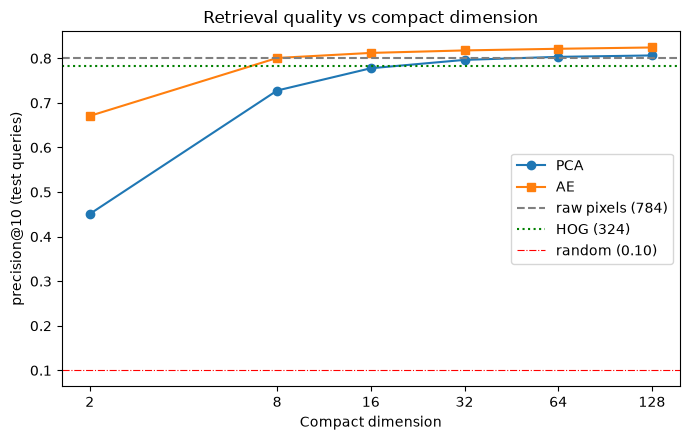

In [4]:
fig, ax = plt.subplots(figsize=(7, 4.5))
for family, marker in [("PCA", "o"), ("AE", "s")]:
    sub = ret_table[ret_table.family == family]
    ax.plot(sub["dim"], sub["p@10"], marker=marker, label=family)
ref = ret_table.set_index("space")
ax.axhline(ref.loc["raw pixels", "p@10"], ls="--", color="gray", label="raw pixels (784)")
ax.axhline(ref.loc["HOG", "p@10"], ls=":", color="green", label="HOG (324)")
ax.axhline(0.10, ls="-.", color="red", lw=0.8, label="random (0.10)")
ax.set_xscale("log", base=2)
ax.set_xticks(DIMS, labels=DIMS)
ax.set_xlabel("Compact dimension")
ax.set_ylabel("precision@10 (test queries)")
ax.set_title("Retrieval quality vs compact dimension")
ax.legend()
plt.tight_layout()
plt.savefig("results/figures/12_precision_vs_dim.png", dpi=150, bbox_inches="tight")
plt.show()

**Célula 5 – classificação vs retrieval lado a lado (primeira espreitadela à conclusão):**

In [5]:
clf = pd.concat([pd.read_csv("results/tables/09_classification_table.csv"),
                 pd.read_csv("results/tables/10_hog_classification.csv")])
clf["space"] = clf.apply(lambda r: r["space"] if r["space"] in ["raw pixels", "HOG"]
                         else f"{r['space']}-{r['dim']}", axis=1)

both = clf[["space", "test_acc"]].merge(ret_table[["space", "p@10"]], on="space")
both["rank_classification"] = both["test_acc"].rank(ascending=False).astype(int)
both["rank_retrieval"] = both["p@10"].rank(ascending=False).astype(int)
both = both.sort_values("rank_classification")
print(both.round(4).to_string(index=False))
both.to_csv("results/tables/12_classification_vs_retrieval.csv", index=False)

     space  test_acc   p@10  rank_classification  rank_retrieval
    AE-128    0.8576 0.8243                    1               1
       HOG    0.8444 0.7821                    2              10
     AE-64    0.8434 0.8214                    3               2
   PCA-128    0.8414 0.8064                    4               5
raw pixels    0.8329 0.8004                    5               8
    PCA-64    0.8324 0.8033                    6               6
     AE-32    0.8234 0.8177                    7               3
    PCA-32    0.8154 0.7965                    8               9
     AE-16    0.8012 0.8121                    9               4
    PCA-16    0.7870 0.7777                   10              11
      AE-8    0.7664 0.8008                   11               7
     PCA-8    0.7302 0.7277                   12              12
      AE-2    0.6166 0.6708                   13              13
     PCA-2    0.5093 0.4507                   14              14
